In [21]:
import numpy as np
import pandas as pd
from scipy.linalg import svd
import matplotlib.pyplot as plt
import time
import os

from sklearn.preprocessing import StandardScaler

from KRR_utils import *
from nystrom_functions import *

# Investigation of the singular values of K matrix

First, we look at the singular values of $K$ when using the real dataset Superconductivity and a linear kernel

In [22]:
os.makedirs("Results", exist_ok=True)

df = pd.read_csv("../Data/train.csv")

X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

print(X.shape)
print(y.shape)

(21263, 81)
(21263,)


In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n_all = X_scaled.shape[0]
entries = n_all*n_all
memory_gb = entries*8/(1024**3)

print("full dataset n =", n_all)
print("full K entries =", entries)
print("full K memory in GB =", memory_gb)

full dataset n = 21263
full K entries = 452115169
full K memory in GB = 3.3685205057263374


In [24]:
rng = np.random.default_rng(1)

sample_n = 3000
sample_ind = rng.choice(X_scaled.shape[0], size=sample_n, replace=False)

data = X_scaled[sample_ind]
target = y[sample_ind]

print(data.shape)
print(target.shape)

(3000, 81)
(3000,)


Linear kernel singular values:

In [25]:
kernel = linear

start = time.time()

K = make_kernel_matrix(data, kernel)
sing_valK = svd(K, compute_uv=False)

end = time.time()

print("runtime =", end-start)
print("largest singular value =", sing_valK[0])
print("smallest singular value =", sing_valK[-1])

runtime = 4.392400741577148
largest singular value = 95446.8715484907
smallest singular value = 6.027724934617129e-31


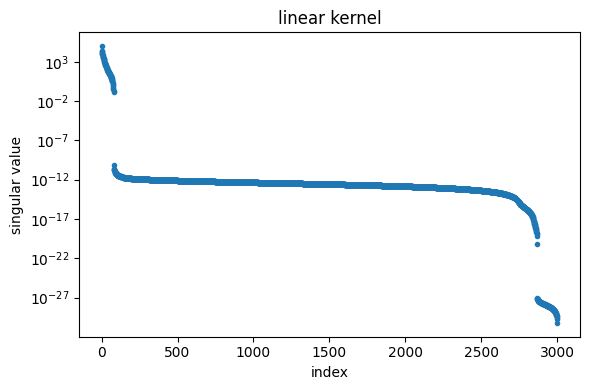

In [26]:
plt.figure(figsize=(6,4))
plt.semilogy(sing_valK, ".")
plt.xlabel("index")
plt.ylabel("singular value")
plt.title("linear kernel")
plt.tight_layout()
plt.savefig("../Results/sing_vals_linear_kernel.pdf")
plt.show()

Gaussian RBF kernel singular values:

In [27]:
gamma = 1/data.shape[1]

def rbf_kernel(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

kernel = rbf_kernel

start = time.time()

K = make_kernel_matrix(data, kernel)
sing_valK = svd(K, compute_uv=False)

end = time.time()

print("gamma =", gamma)
print("runtime =", end-start)
print("largest singular value =", sing_valK[0])
print("smallest singular value =", sing_valK[-1])

gamma = 0.012345679012345678
runtime = 5.323451280593872
largest singular value = 1091.910485774429
smallest singular value = 3.7268981689987524e-22


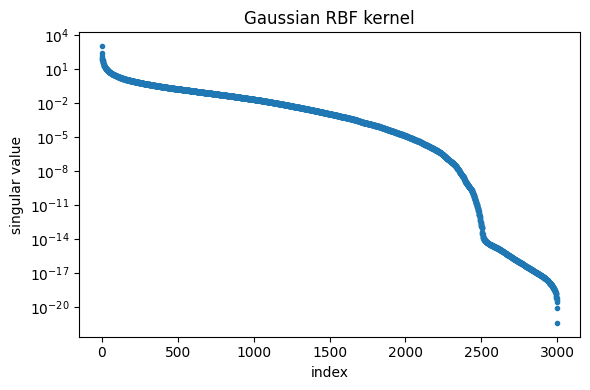

In [28]:
plt.figure(figsize=(6,4))
plt.semilogy(sing_valK, ".")
plt.xlabel("index")
plt.ylabel("singular value")
plt.title("Gaussian RBF kernel")
plt.tight_layout()
plt.savefig("../Results/sing_vals_rbf_kernel.pdf")
plt.show()

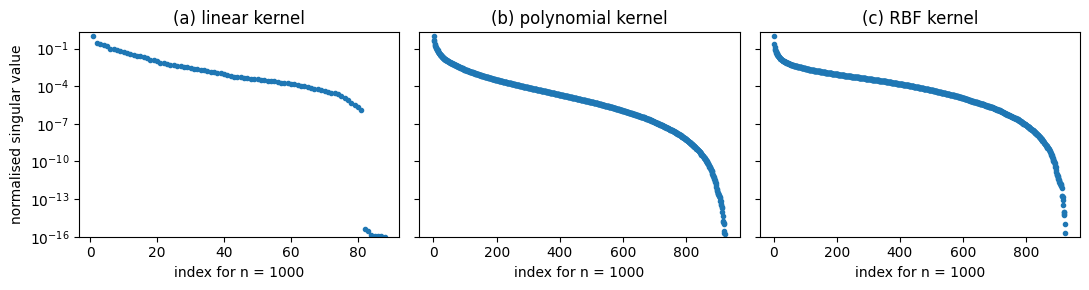

In [29]:
# Three kernel singular value plots next to each other
# Sample size above 81 did not make a difference to the shape of the plots

n = 1000
ind = rng.choice(X_scaled.shape[0], size=n, replace=False)
data = X_scaled[ind]
gamma = 1/X_scaled.shape[1]

def rbf1(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

kernel_list = [
    ("(a) linear", linear),
    ("(b) polynomial", poly),
    ("(c) RBF", rbf1),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)

for ax, (name, func) in zip(axes, kernel_list):
    K = make_kernel_matrix(data, func)
    sing_val = svd(K, compute_uv=False)
    sing_val = sing_val / sing_val[0]

    # Stopping once the tail is around 10^-16
    below = np.where(sing_val < 1e-16)[0]
    if len(below) > 0:
        stop = below[0] + 1
    else:
        stop = len(sing_val)

    ax.semilogy(np.arange(1, stop + 1), sing_val[:stop], ".")
    ax.set_title(name + " kernel")
    ax.set_xlabel("index for n = " + str(n))
    ax.set_ylim(1e-16, 2)

axes[0].set_ylabel("normalised singular value")

plt.tight_layout()
plt.savefig("../Results/sing_val_three_kernels.pdf")
plt.show()

In [30]:
# Time K construction as n increases

ns = [100, 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]
rows = []
gamma = 1/X_scaled.shape[1]

def rbf2(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

kernel_list2 = [
    ("linear", linear),
    ("polynomial", poly),
    ("RBF", rbf2),
]

for n in ns:
    ind = rng.choice(X_scaled.shape[0], size=n, replace=False)
    X = X_scaled[ind]

    for name, func in kernel_list2:
        start = time.perf_counter()
        K = make_kernel_matrix(X, func)
        rows.append([n, name, time.perf_counter() - start])

tdf = pd.DataFrame(rows, columns=["n", "kernel", "time"])
tdf.to_csv("../Results/kernel_construction_time.csv", index=False)
tdf

,n,kernel,time
0,100,linear,0.000888
1,100,polynomial,0.000429
2,100,RBF,0.003175
3,200,linear,0.000670
4,200,polynomial,0.001122
5,200,RBF,0.003728
6,400,linear,0.001797
7,400,polynomial,0.002609
8,400,RBF,0.010434
9,600,linear,0.004073


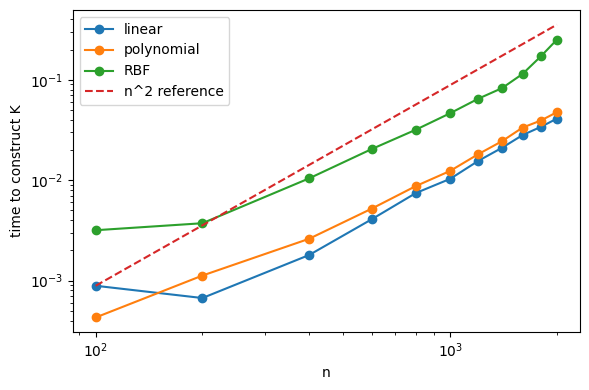

In [31]:
# Plot with references
plt.figure(figsize=(6, 4))  

for name in tdf["kernel"].unique():
    part = tdf[tdf["kernel"] == name]
    plt.loglog(part["n"], part["time"], marker="o", label=name)

# reference n^2 line, scaled to the linear kernel first point
ref_n = np.array(ns, dtype=float)
first_time = tdf[(tdf["kernel"] == "linear") & (tdf["n"] == ns[0])]["time"].iloc[0]
ref = first_time * (ref_n / ref_n[0])**2
plt.loglog(ref_n, ref, linestyle="--", label="n^2 reference")

plt.xlabel("n")
plt.ylabel("time to construct K")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/kernel_construction_time.pdf")
plt.show()

In [40]:
ns = [10, 100, 200, 500, 1000, 2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000]
plot_ns = ns[1:]   # n=10 is just a warm-up, it is not part of the result table or plot
rows = []
lam = 1e-2

for q in range(len(ns)):
    n = ns[q]
    ind = rng.choice(X_scaled.shape[0], size=n, replace=False)
    X = X_scaled[ind]
    y_now = y[ind]

    start = time.perf_counter()
    
    K = make_kernel_matrix(X, rbf2)
   
    construct_time = time.perf_counter() - start

    start = time.perf_counter()
    
    A = K + lam*np.eye(n)
    L = cholesky(A, lower=True)
    z = solve_triangular(L, y_now, lower=True)
    alpha = solve_triangular(L.T, z, lower=False)

    solve_time = time.perf_counter() - start

    #skip n=10 because there is some warm-up time that dominates the solve time seen in a few trials with different starting n
    if q == 0:
        continue

    rows.append([n, "construct K", construct_time])
    rows.append([n, "solve linear system", solve_time])

solve_df = pd.DataFrame(rows, columns=["n", "part", "time"])
solve_df.to_csv("../Results/construct_vs_solve_time.csv", index=False)
solve_df

,n,part,time
0,100,construct K,0.001808
1,100,solve linear system,0.000142
2,200,construct K,0.004045
3,200,solve linear system,0.000680
4,500,construct K,0.016127
5,500,solve linear system,0.003576
6,1000,construct K,0.051360
7,1000,solve linear system,0.016145
8,2000,construct K,0.296696
9,2000,solve linear system,0.069644


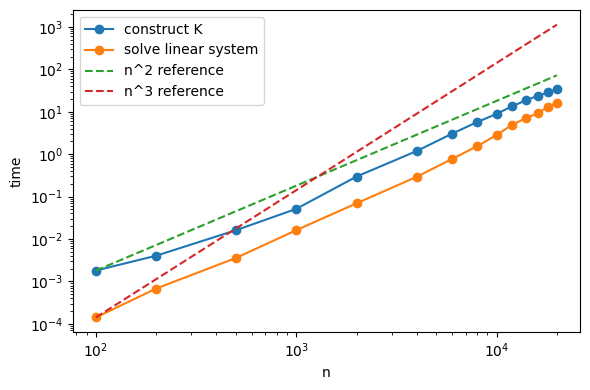

In [41]:
# Plot
plt.figure(figsize=(6, 4))

for name in solve_df["part"].unique():
    part = solve_df[solve_df["part"] == name]
    plt.loglog(part["n"], part["time"], marker="o", label=name)

ref_n = np.array(plot_ns, dtype=float)
base_n = plot_ns[0]

base_construct = solve_df[
    (solve_df["part"] == "construct K") & (solve_df["n"] == base_n)
]["time"].iloc[0]

base_solve = solve_df[
    (solve_df["part"] == "solve linear system") & (solve_df["n"] == base_n)
]["time"].iloc[0]

plt.loglog(ref_n, base_construct * (ref_n/ref_n[0])**2, linestyle="--", label="n^2 reference")
plt.loglog(ref_n, base_solve * (ref_n/ref_n[0])**3, linestyle="--", label="n^3 reference")

plt.xlabel("n")
plt.ylabel("time")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/construct_vs_solve_time.pdf")
plt.show()

In [34]:
# MSE and lambda plot

train_size = 800
test_size = 200
perm = rng.permutation(X_scaled.shape[0])
train_ind = perm[:train_size]
test_ind = perm[train_size:train_size + test_size]
X_train = X_scaled[train_ind]
y_train = y[train_ind]
X_test = X_scaled[test_ind]
y_test = y[test_ind]
lambdas = np.logspace(-5, 3, 9)
mse_rows = []
K_train = make_kernel_matrix(X_train, rbf2)
K_test = rbf2(X_test, X_train)

for lam in lambdas:
    alpha = np.linalg.solve(K_train + lam*np.eye(train_size), y_train)
    pred = K_test @ alpha
    mse = np.mean((pred - y_test)**2)
    mse_rows.append([lam, mse])

mse_df = pd.DataFrame(mse_rows, columns=["lambda", "test_mse"])
mse_df.to_csv("../Results/mse_vs_lambda.csv", index=False)
mse_df

,lambda,test_mse
0,0.00001,2088.249970
1,0.00010,1120.500084
2,0.00100,475.358426
3,0.01000,296.272464
4,0.10000,287.385996
5,1.00000,313.157366
6,10.00000,403.702510
7,100.00000,679.531277
8,1000.00000,1587.228492


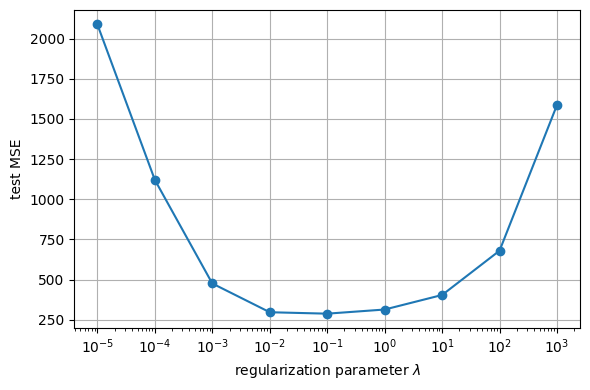

In [45]:
# Plot MSE against lambda
plt.figure(figsize=(6, 4))
plt.semilogx(mse_df["lambda"], mse_df["test_mse"], marker="o")
plt.xlabel("regularization parameter $\lambda$")
plt.ylabel("test MSE")
plt.grid(True)
plt.tight_layout()
plt.savefig("../Results/mse_vs_lambda.pdf")
plt.show()

In [36]:
# Fixed test set while increasing train set size

train_sizes = [100, 200, 400, 800, 1000, 1200, 1400, 1600]
test_size = 200
perm = rng.permutation(X_scaled.shape[0])
fixed_test_ind = perm[:test_size]
train_set_ind = perm[test_size:]
X_test = X_scaled[fixed_test_ind]
y_test = y[fixed_test_ind]
rows = []
lam = 1e-2

for train_size in train_sizes:
    train_ind = train_set_ind[:train_size]
    X_train = X_scaled[train_ind]
    y_train = y[train_ind]

    start = time.perf_counter()

    K_train = make_kernel_matrix(X_train, rbf2)
    alpha = np.linalg.solve(K_train + lam*np.eye(train_size), y_train) #may swap to CG
    K_test = rbf2(X_test, X_train)
    pred = K_test @ alpha
    
    total_time = time.perf_counter() - start

    mse = np.mean((pred - y_test)**2)
    rows.append([train_size, mse, total_time])

inct_df = pd.DataFrame(rows, columns=["train_size", "test_mse", "time"])
inct_df.to_csv("../Results/mse_time_vs_train_size.csv", index=False)
inct_df

,train_size,test_mse,time
0,100,383.526667,0.005612
1,200,264.204433,0.060698
2,400,214.690751,0.326428
3,800,176.388738,0.714470
4,1000,184.446745,0.633995
5,1200,186.620474,0.730388
6,1400,176.499246,0.554767
7,1600,166.409530,0.628106


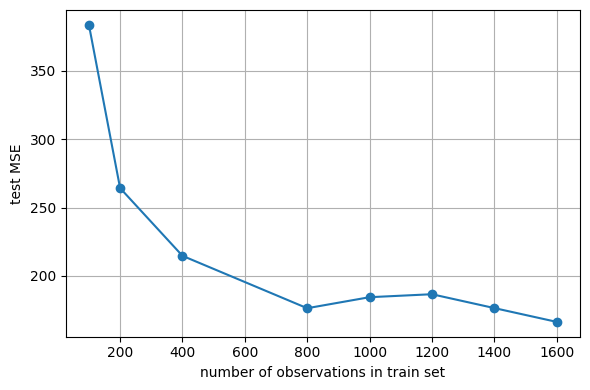

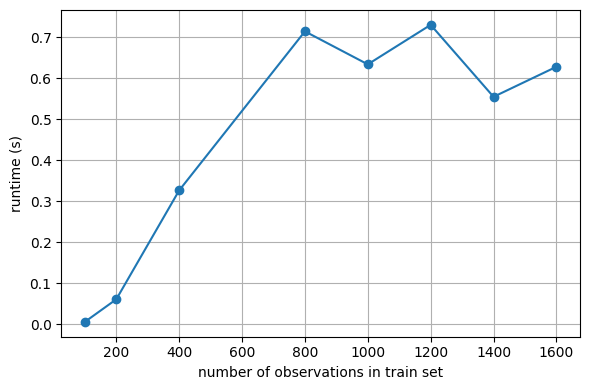

In [48]:
# MSE and runtime plots

plt.figure(figsize=(6, 4))
plt.plot(inct_df["train_size"], inct_df["test_mse"], marker="o")
plt.xlabel("number of observations in train set")
plt.ylabel("test MSE")
plt.grid(True)
plt.tight_layout()
plt.savefig("../Results/mse_vs_train_size.pdf")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(inct_df["train_size"], inct_df["time"], marker="o")
plt.xlabel("number of observations in train set")
plt.ylabel("runtime (s)")
plt.grid(True)
plt.tight_layout()
plt.savefig("../Results/runtime_vs_train_size.pdf")
plt.show()